# TTS-Lab · Speech-model-v4-TTS

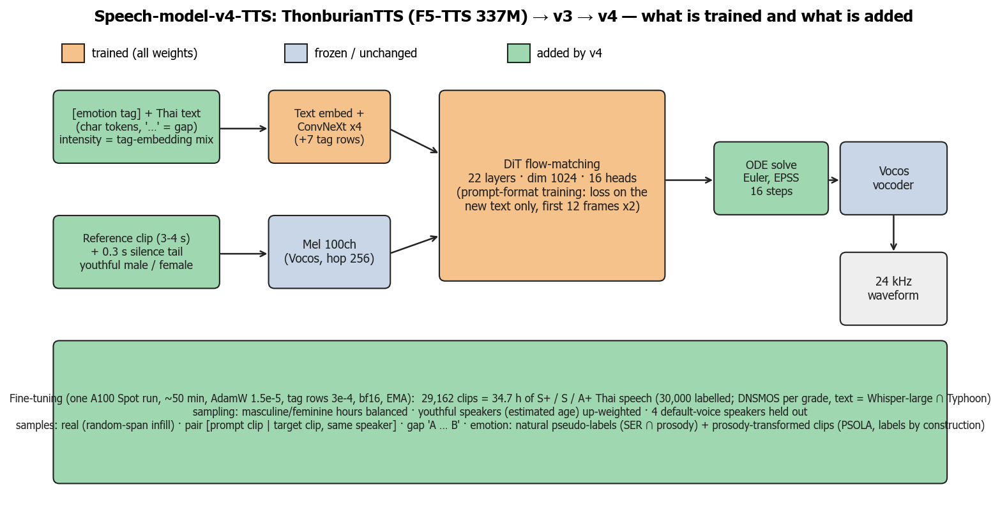

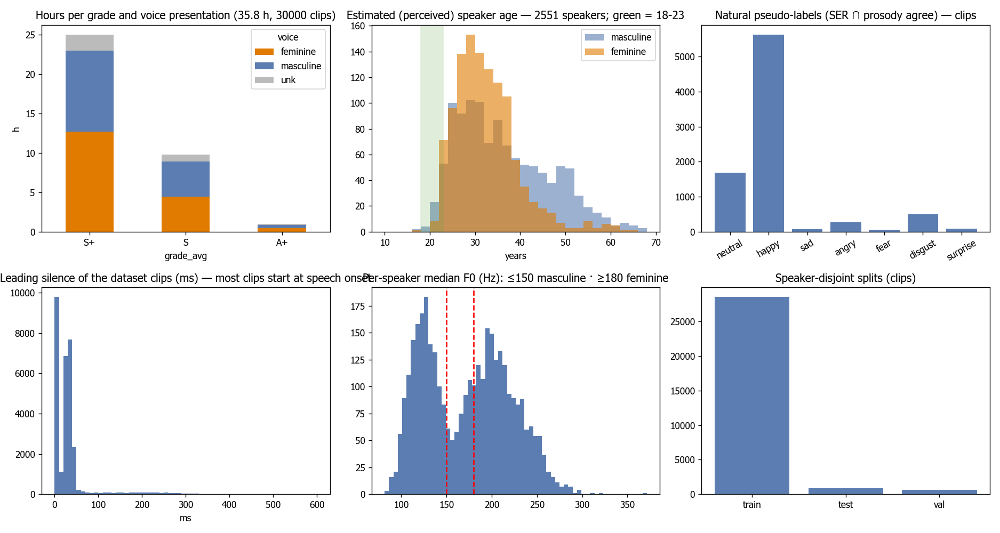

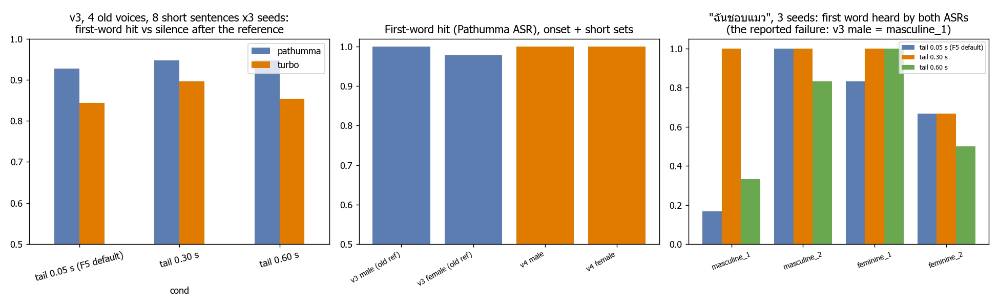

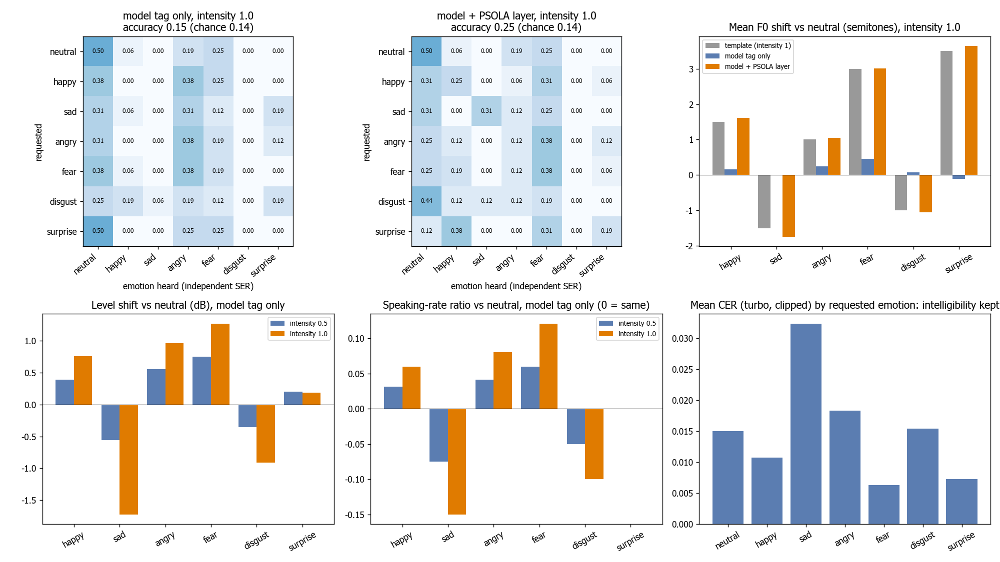

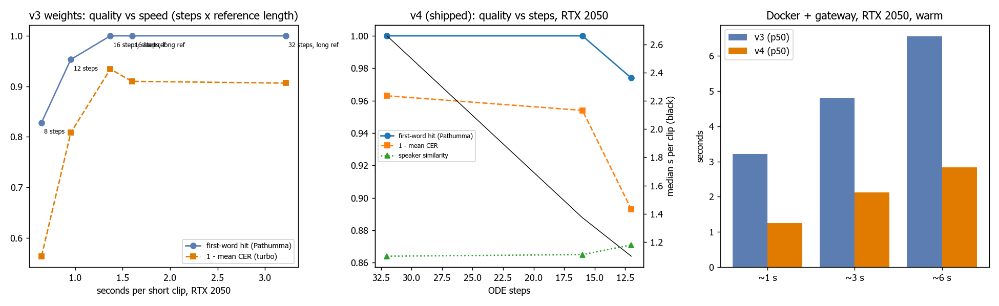

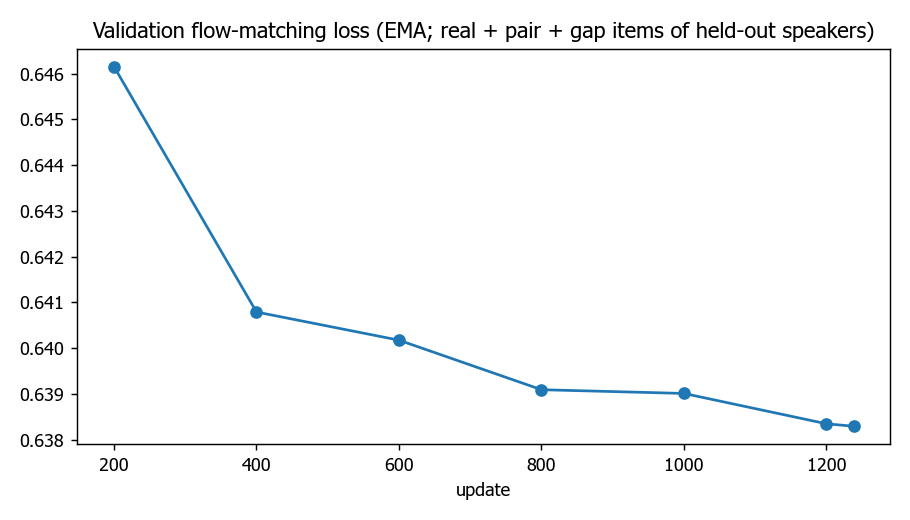

In [1]:
from IPython.display import Image, Audio, display
for f in ("architecture", "data", "onset", "emotion", "latency", "results"):
    p = f"figures/{f}.png"
    import os
    if os.path.exists(p):
        display(Image(filename=p))

In [2]:
import sys, time, numpy as np
sys.path.insert(0, "../models/Speech-model-v4-TTS")
from tts import Speech
s = Speech("../models/Speech-model-v4-TTS")

def play(text, voice="male", label="", **k):
    t = time.time(); y, sr = s.say(text, voice=voice, seed=0, **k)
    print(f"{label or voice}: {len(y) / sr:.1f} s of speech in {time.time() - t:.1f} s")
    display(Audio(y, rate=sr))

C:\Users\BM MONEY\miniconda3\envs\490-TTS\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1102 00:27:08.368000 14868 site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


Download Vocos from huggingface charactr/vocos-mel-24khz



vocab :  ..\models\Speech-model-v4-TTS\vocab.txt
token :  custom
model :  ..\models\Speech-model-v4-TTS\model.safetensors 




ref_text   ในการได้รับรู้สารสนเทศ ข่าวสารข้อมูล. 


## a) plain text, no expression (= neutral)

In [3]:
for v in ("male", "female"):
    play("สวัสดีครับ วันนี้อากาศดีมาก ไปเดินเล่นที่สวนสาธารณะกันไหม", v)

male: 5.7 s of speech in 2.6 s



ref_text   ของการที่จะต้องเข้าใจจริยธรรมนะคะ. 


female: 5.2 s of speech in 2.4 s


## b) 7 sentences

In [4]:
import evaluate as ev
for t in ev.SENTENCES:
    for v in ("male", "female"):
        play(t, v, label=f"{v} | {t[:24]}")

male | สวัสดีครับ วันนี้อากาศดี: 5.7 s of speech in 2.3 s


female | สวัสดีครับ วันนี้อากาศดี: 5.2 s of speech in 2.1 s


male | ฉันอยากไปโรงพยาบาลเพราะร: 4.1 s of speech in 2.1 s


female | ฉันอยากไปโรงพยาบาลเพราะร: 3.7 s of speech in 1.9 s


male | คุณแม่ทำอาหารอร่อยมากเลย: 5.1 s of speech in 2.4 s


female | คุณแม่ทำอาหารอร่อยมากเลย: 4.6 s of speech in 2.1 s


... (4 outputs left out)

male | ทำไมวันนี้ถึงมาสายล่ะ มี: 4.6 s of speech in 2.3 s


female | ทำไมวันนี้ถึงมาสายล่ะ มี: 4.1 s of speech in 2.0 s


male | เด็กๆ ดีใจมากเมื่อได้รับ: 4.8 s of speech in 2.3 s


female | เด็กๆ ดีใจมากเมื่อได้รับ: 4.3 s of speech in 2.1 s


## c) 5 x 5 words

In [5]:
for group, ws in ev.WORDS.items():
    for w in ws.split():
        play(w, "female", label=f"{group} | {w}")

ครอบครัว | พ่อ: 0.9 s of speech in 1.5 s


ครอบครัว | แม่: 0.9 s of speech in 1.3 s


ครอบครัว | พี่: 0.9 s of speech in 1.3 s


ครอบครัว | น้อง: 0.9 s of speech in 1.3 s


ครอบครัว | ลูก: 0.9 s of speech in 1.3 s


อาหาร | ข้าว: 0.9 s of speech in 1.3 s


... (15 outputs left out)

ความรู้สึก | เสียใจ: 0.9 s of speech in 1.3 s


ความรู้สึก | เหนื่อย: 0.9 s of speech in 1.3 s


ความรู้สึก | หิว: 0.9 s of speech in 1.3 s


ความรู้สึก | รัก: 0.9 s of speech in 1.3 s


## d) gap sentences

In [6]:
for t in ev.GAPS:
    for v in ("male", "female"):
        play(t, v, label=f"{v} | {t}")

male | ฉัน … แม่: 1.5 s of speech in 1.6 s


female | ฉัน … แม่: 1.4 s of speech in 1.7 s


male | ฉันอยากไปประเทศ …: 2.4 s of speech in 1.8 s


female | ฉันอยากไปประเทศ …: 2.2 s of speech in 1.6 s


male | พรุ่งนี้ … จะไปตลาดกับ … ที่บ้าน: 4.4 s of speech in 2.3 s


female | พรุ่งนี้ … จะไปตลาดกับ … ที่บ้าน: 4.1 s of speech in 2.0 s


## e) expression: one text, every emotion, then sequences and an intensity sweep

In [7]:
for v in ("male", "female"):
    for e in ev.EMOTIONS:
        play("ฉันไม่คิดว่าจะเป็นแบบนี้", v, label=f"{v} | {e}", emotion=e)

male | neutral: 2.5 s of speech in 1.8 s


male | happy: 2.4 s of speech in 1.8 s


male | sad: 2.7 s of speech in 1.6 s


male | angry: 2.4 s of speech in 1.7 s


male | fear: 2.3 s of speech in 1.7 s


male | disgust: 2.6 s of speech in 1.7 s


... (4 outputs left out)

female | angry: 2.1 s of speech in 1.4 s


female | fear: 2.1 s of speech in 1.4 s


female | disgust: 2.3 s of speech in 1.4 s


female | surprise: 2.2 s of speech in 1.4 s


In [8]:
play([("ดีใจจัง", "happy"), ("แล้วไงต่อ", "surprise")], "female", label="sequence happy → surprise")
play([("ฉันเสียใจมาก", "sad"), ("แต่ไม่เป็นไรนะ", "neutral")], "male", label="sequence sad → neutral")
for e in ("happy", "sad", "angry"):
    for i in (0.0, 0.25, 0.5, 1.0):
        play("วันนี้เป็นวันที่ฉันรอคอยมานาน", "female", label=f"{e} intensity {i}", emotion=e, intensity=i)

sequence happy → surprise: 1.9 s of speech in 2.7 s


sequence sad → neutral: 2.9 s of speech in 3.2 s


happy intensity 0.0: 2.7 s of speech in 1.7 s


happy intensity 0.25: 2.6 s of speech in 1.5 s


happy intensity 0.5: 2.6 s of speech in 1.5 s


happy intensity 1.0: 2.5 s of speech in 1.5 s


... (4 outputs left out)

angry intensity 0.0: 2.7 s of speech in 2.0 s


angry intensity 0.25: 2.6 s of speech in 2.2 s


angry intensity 0.5: 2.6 s of speech in 1.7 s


angry intensity 1.0: 2.5 s of speech in 1.6 s


## f) onset regression: the first word is kept (male and female)

In [9]:
for t in ("ฉันชอบแมว", "ผมชอบแมว", "ฉันรักแม่", "คุณชอบไหม", "วันนี้ฝนตก"):
    for v in ("male", "female"):
        play(t, v, label=f"{v} | {t}")

male | ฉันชอบแมว: 0.9 s of speech in 1.6 s


female | ฉันชอบแมว: 0.9 s of speech in 1.3 s


male | ผมชอบแมว: 0.9 s of speech in 1.2 s


female | ผมชอบแมว: 0.9 s of speech in 1.3 s


male | ฉันรักแม่: 0.9 s of speech in 1.2 s


female | ฉันรักแม่: 0.9 s of speech in 1.3 s


male | คุณชอบไหม: 0.9 s of speech in 1.2 s


female | คุณชอบไหม: 0.9 s of speech in 1.3 s


male | วันนี้ฝนตก: 1.0 s of speech in 1.5 s


female | วันนี้ฝนตก: 0.9 s of speech in 1.3 s


## g) latency: v3 vs v4, same machine, warm

In [10]:
import json
from pathlib import Path
v3 = Speech("../models/Speech-model-v3-TTS"); v3.ref_tail_s = 0.05          # v3 exactly as shipped: 32 steps, old reference, 50 ms tail
def timeit(m, text, voice, n=5, **k):
    m.say(text, voice=voice, seed=0, **k); ts = []
    for i in range(n):
        t = time.perf_counter(); y, sr = m.say(text, voice=voice, seed=i, **k)
        ts.append(time.perf_counter() - t)
    return np.median(ts), len(y) / sr
for k, text in ev.LAT.items():
    a, da = timeit(v3, text, "masculine_1", nfe=32); b, db = timeit(s, text, "male")
    print(f"{k}:  v3 {a:.2f} s for {da:.1f} s of speech   |   v4 {b:.2f} s for {db:.1f} s of speech   ({a / b:.1f}x faster)")

Download Vocos from huggingface charactr/vocos-mel-24khz



vocab :  ..\models\Speech-model-v3-TTS\vocab.txt
token :  custom
model :  ..\models\Speech-model-v3-TTS\model.safetensors 




ref_text   แล้วก็ปลายสายกระบอกฉีดก็จะเป็น ท่อยางสีดำ ๆ นะครับ. 


1s:  v3 3.23 s for 1.0 s of speech   |   v4 1.21 s for 0.9 s of speech   (2.7x faster)


3s:  v3 4.99 s for 5.0 s of speech   |   v4 2.09 s for 4.7 s of speech   (2.4x faster)


6s:  v3 6.70 s for 8.7 s of speech   |   v4 2.77 s for 8.2 s of speech   (2.4x faster)
